In [1]:
test_file_name = "test1.txt"
testing = True

In [2]:
from pathlib import Path
import sys

# --- Path Calculations ---

SCRIPT_DIR = Path(sys.argv[0]).resolve().parent.parent.parent
PROJECT_ROOT = SCRIPT_DIR.parent.parent


# Define the directory containing 'keymaerax_parser.py' and 'ast_config.py'
# (e.g., 'project_root/AST_parser/')

parser_module_dir = PROJECT_ROOT / "KyxParser"
src_dir = parser_module_dir / "AST_parser"

# Add the parser module directory to Python's system path
if str(parser_module_dir) not in sys.path:
    sys.path.insert(0, str(parser_module_dir))
    print(f"Added '{parser_module_dir}' to sys.path.")
else:
    print(f"'{parser_module_dir}' already in sys.path.")

# Define test input and expected output directories relative to SCRIPT_DIR
# Based on the file explorer, 'input' and 'output_AST' are direct subdirectories of 'test'.
TEST_INPUT_DIR = parser_module_dir / "test" / "input" / "withReward"

# --- Debugging prints for paths ---
print(f"Project Root: {PROJECT_ROOT.resolve()}")
print(f"Script Directory: {SCRIPT_DIR.resolve()}")
print(f"Parser Module Directory: {src_dir.resolve()}")
print(f"Test Input Directory: {TEST_INPUT_DIR.resolve()}")

# --- How to get the content of test1.txt ---

# 1. Construct the full path to test1.txt
test_path = TEST_INPUT_DIR / test_file_name
content = None

print(f"\nAttempting to read: {test_path.resolve()}")

# 2. Read the content of the file
try:
    # Use 'with open(...)' for safe file handling (ensures file is closed)
    with open(test_path, 'r', encoding='utf-8') as f:
        content = f.read()
    print(f"Successfully read '{test_file_name}'. Content length: {len(content)} characters.")
    print(f"Content preview (first 200 chars):\n{content}")  # Print a preview of the content

except FileNotFoundError:
    print(f"Error: The file '{test_path.resolve()}' was not found.")
    print("Please ensure the file exists at the specified path relative to your project root.")
except Exception as e:
    print(f"An unexpected error occurred while reading the file: {e}")

Added 'D:\Reinforcement learning\KyxParser' to sys.path.
Project Root: D:\Reinforcement learning
Script Directory: D:\Reinforcement learning\kyx_parser\.venv
Parser Module Directory: D:\Reinforcement learning\KyxParser\AST_parser
Test Input Directory: D:\Reinforcement learning\KyxParser\test\input\withReward

Attempting to read: D:\Reinforcement learning\KyxParser\test\input\withReward\test1.txt
Error: The file 'D:\Reinforcement learning\KyxParser\test\input\withReward\test1.txt' was not found.
Please ensure the file exists at the specified path relative to your project root.


In [ ]:
# # PyAST_test.py
# from keymaerax_parser import KeYmaeraXParser, convert_keymaerax_ast_to_intermediate_pyast
# from gym_generator import generate_gym_environment_code # Import the generator

# # --- KeYmaera X Input ---


# # --- Main Execution ---
# if __name__ == "__main__":
#     print("--- Parsing KeYmaera X Input into internal AST ---")
#     parser = KeYmaeraXParser(content)
#     kx_ast = parser.parse()
#     # Print the internal KeYmaera X AST for debugging/verification
#     print(kx_ast) # Commented out for brevity

#     print("\n--- Converting KeYmaera X AST to Intermediate Python AST ---")
#     py_ast_config = convert_keymaerax_ast_to_intermediate_pyast(kx_ast)
#     print("Intermediate Python AST (GymEnvironmentConfig):\n", py_ast_config)

#     print("\n--- Generating Gymnasium environment code ---")
#     if testing:
#         generated_code = generate_gym_environment_code(py_ast_config, envName="GeneratedKXEnv")
#     else:
#         generated_code = generate_gym_environment_code(py_ast_config)

#     # print(generated_code)
#     output_filename = "generated_kx_env.py"
#     with open(src_dir / output_filename, "w") as f:
#         f.write(generated_code)

#     print(f"Generated Gymnasium environment code saved to {output_filename}")

--- Parsing KeYmaera X Input into internal AST ---
[KeYmaeraXSpecification]:
  [TheoremName]: IJRR17/Theorem 1: Static safety
  [DefinitionsBlock]:
    [DEF]: Real ep
    [DEF]: Real b
    [DEF]: Real A
    [DEF]: Real W
    [DEF]: Real stopDist = v^2 / (2*b)
      [Parameters]: Real v
    [DEF]: Real accelComp = ((A/b + 1) * (A/2 * ep^2 + ep*v))
      [Parameters]: Real v
    [DEF]: Real admissibleSeparation = stopDist(v) + accelComp(v)
      [Parameters]: Real v
    [DEF]: Bool isWellformedDir = dx^2 + dy^2 = 1 [Meta: {'type': 'progress', 'reward': '10', 'shape': '-((dx**2 + dy**2) - 1)**2', 'on_success': 'continue:status=none', 'on_failure': 'continue:status=none'}]
      [Parameters]: Real dx, Real dy
    [DEF]: Bool isPhysicallyValid = v >= 0 & r != 0 [Meta: {'type': 'safety', 'penalty': '-500', 'on_failure': 'truncate:status=failure', 'on_success': 'continue:status=none'}]
      [Parameters]: Real v, Real r
    [DEF]: Bool isSafe = abs(x-xo) > stopDist(v) | abs(y-yo) > stopDist(v

TypeError: unsupported operand type(s) for +: 'PosixPath' and 'str'

In [2]:
import gymnasium as gym
# The class name is derived from the Theorem name: "IJRR17/Theorem 1: Static safety"
# spaces, slashes, colons, etc., are replaced with underscores.
from generated_kx_with_cisb import GeneratedKXEnv
import numpy as np

# Instantiate the environment
env = GeneratedKXEnv(cisb_size=1000, cisb_populate_attempts=2000, render_mode="matplotlib")

observation, info = env.reset()
print("Initial observation:", observation)
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)

# Example 1: Choose the first branch: Obstacle movement (index 0 for ChoiceLevel_0)
# Requires 'assign_vxo' and 'assign_vyo'
action_branch_0 = {
    'choice_ChoiceLevel_0': 0, # Select the obstacle movement branch (index 0)
    'assign_vxo': 0.1,         # Example value for vxo (constrained by V)
    'assign_vyo': 0.2,         # Example value for vyo (constrained by V)
    'choice_ChoiceLevel_1': 0, # Dummy value for unused nested choice
    'assign_v': 0.0,           # Dummy value for unused nondeterministic assignments
    'assign_w': 0.0,
    'assign_r': 0.0,
    'assign_xo': 0.0,
    'assign_yo': 0.0,
}

print("\nTaking 5 steps with action_branch_0 (obstacle movement):")
for i in range(5):
    observation, reward, terminated, truncated, info = env.step(action_branch_0)
    print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
    if terminated or truncated:
        print("Episode finished.")
        break
env.close()

# Example 2: Reset and choose the agent movement branch (index 1 for ChoiceLevel_0)
# Then, within agent movement, choose the 'agent moves' sub-branch (index 1 for ChoiceLevel_1)
print("\nResetting environment and taking 5 steps with action_branch_2 (agent moves):")
observation, info = env.reset()

action_branch_2 = {
    'choice_ChoiceLevel_0': 1, # Select the agent movement branch (index 1)
    'choice_ChoiceLevel_1': 1, # Select the agent *moving* sub-branch (index 1 within ChoiceLevel_1)
    'assign_vxo': 0.0,         # Dummy value for unused obstacle assignment
    'assign_vyo': 0.0,         # Dummy value for unused obstacle assignment
    'assign_v': 1.0,           # Example value for v (must be >= 0)
    'assign_w': 0.1,           # Example value for w (within -W to W, assuming W=0.5)
    'assign_r': 10.0,          # Example value for r (r != 0 and r*w == v) - make sure this holds!
                               # Here: 10.0 * 0.1 = 1.0, so r*w == v is satisfied.
    'assign_xo': 10.0,         # Example value for xo
    'assign_yo': 0.0,          # Example value for yo
}

for i in range(5):
    observation, reward, terminated, truncated, info = env.step(action_branch_2)
    print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
    if terminated or truncated:
        print("Episode finished.")
        break

env.close()

# Example 3: Reset and choose the agent movement branch (index 1 for ChoiceLevel_0)
# Then, within agent movement, choose the 'agent stops' sub-branch (index 0 for ChoiceLevel_1)
print("\nResetting environment and taking 5 steps with action_branch_3 (agent stops):")
observation, info = env.reset()

action_branch_3 = {
    'choice_ChoiceLevel_0': 1, # Select the agent movement branch (index 1)
    'choice_ChoiceLevel_1': 0, # Select the agent *stops* sub-branch (index 0 within ChoiceLevel_1)
    'assign_vxo': 0.0,         # Dummy value for unused obstacle assignment
    'assign_vyo': 0.0,         # Dummy value for unused obstacle assignment
    'assign_v': 0.0,           # Dummy value, as v will be set to 0 by deterministic assignment
    'assign_w': 0.0,           # Dummy value, as w will be set to 0 by deterministic assignment
    'assign_r': 0.0,           # Dummy value for unused nondeterministic assignments
    'assign_xo': 0.0,
    'assign_yo': 0.0,
}

for i in range(5):
    observation, reward, terminated, truncated, info = env.step(action_branch_3)
    print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
    if terminated or truncated:
        print("Episode finished.")
        break

env.close()

Populating Contrastive Initial State Buffer (CISB) with 1000 diverse states using Z3.Optimize...
Z3 UNKNOWN during CISB population attempt 1. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 2. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 3. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 4. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 5. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 8. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 9. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 10. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 12. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 13. Retrying with new soft constraints.
Z3 UNKNOWN during CISB population attempt 14. Retrying with new soft constraints.
Z3 UNKNO

In [2]:
# Assuming your modified GeneratedKXEnv is in 'your_env_file.py'
# from your_env_file import GeneratedKXEnv

# 1. Create the environment
# You can set render_mode here, or pass it to env.render() later.
# env = GeneratedKXEnv(render_mode="matplotlib") # Or omit here and specify in render() call

# 2. Run an episode to collect data
obs, info = env.reset()
done = False
total_reward = 0

print("Starting episode...")
for i in range(env.max_episode_steps):
    # Example: A dummy action for the Dict action space
    # In a real scenario, this would come from your reinforcement learning agent
    action = {
        'choice_ChoiceLevel_0': env.action_space['choice_ChoiceLevel_0'].sample(),
        'assign_w': env.action_space['assign_w'].sample(),
        'assign_r': env.action_space['assign_r'].sample(),
        'assign_xo': env.action_space['assign_xo'].sample(),
        'assign_yo': env.action_space['assign_yo'].sample(),
    }

    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward

    # Optional: print current state or reward
    # print(f"Step {i+1}: State={env.state}, Reward={reward}, Terminated={terminated}, Truncated={truncated}")

    if terminated or truncated:
        print(f"Episode finished after {i+1} steps with total reward: {total_reward}")
        break
else:
    print(f"Episode finished after {env.max_episode_steps} steps (truncated) with total reward: {total_reward}")

# 3. Generate and display the matplotlib plot
# You can specify which variables you want to see.
# If variables_to_plot is None, it will plot all state variables except 't'.
env.render(mode="matplotlib", variables_to_plot=['x', 'y', 'v', 'w', 'a'])

# 4. Close the environment
env.close()

print("Environment closed.")

NameError: name 'env' is not defined

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Setting up environment for training...
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 1. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 2. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 3. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 4. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 5. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 6. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 8. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 9. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 10. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during CISB population attempt 11. Retrying with new soft constraints.
DEBUG_CISB: Z3 UNKNOWN during

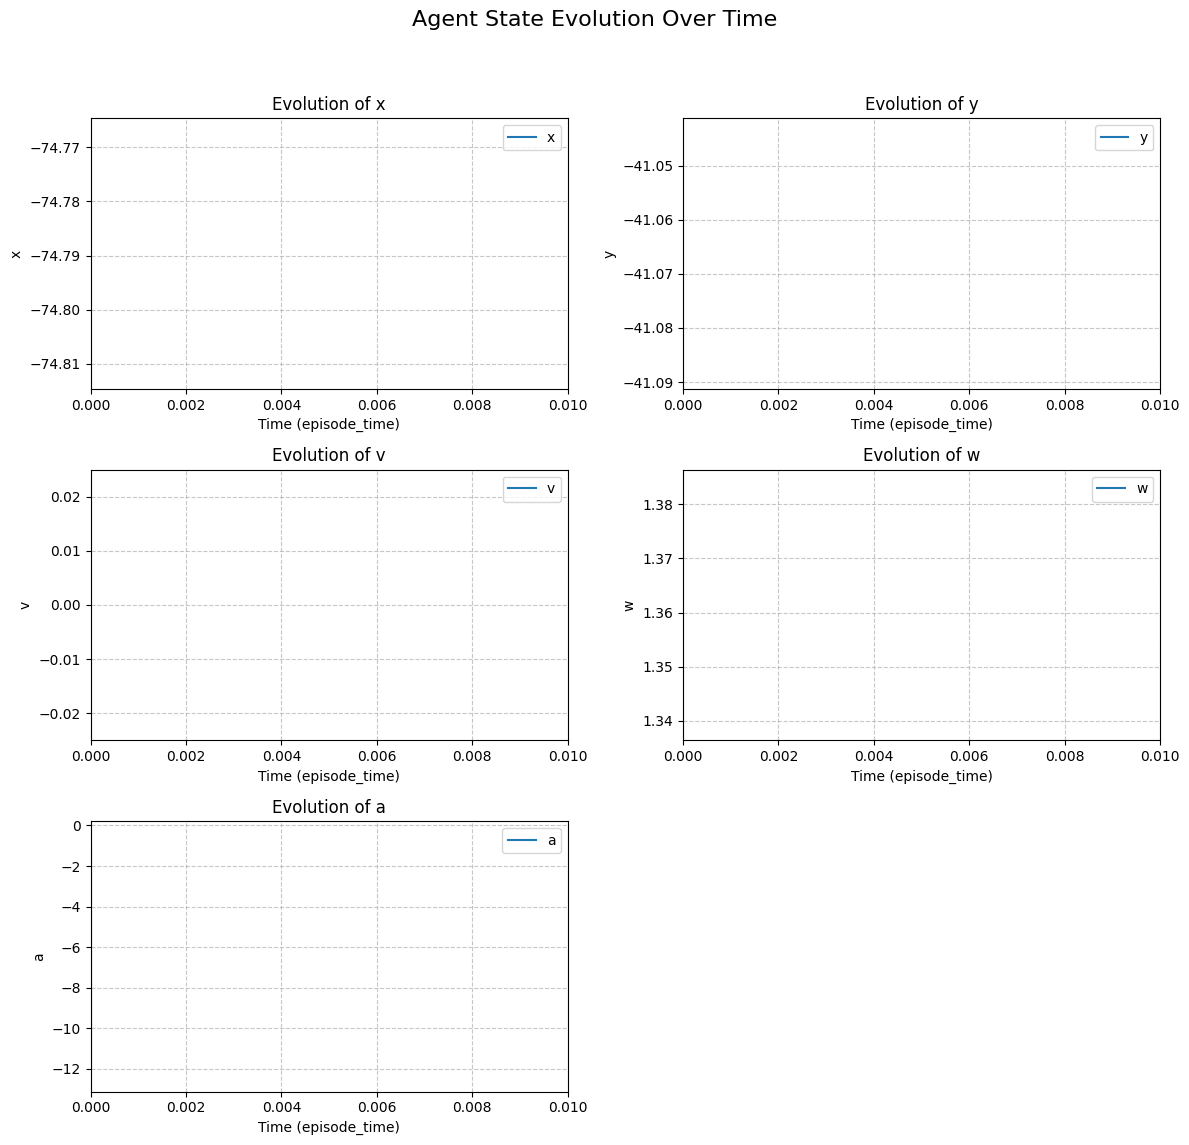

Test complete.


In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
# Assuming GeneratedKXEnv is imported from another file
from generated_kx_with_cisb import GeneratedKXEnv

# --- Wrapper to convert Dict Action Space to Box Action Space ---
class FlattenActionDictWrapper(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        # The original action space (assuming it's a Dict as described in your error)
        original_action_space = env.action_space

        # Define the new flattened action space
        # It will be a Box space of shape (5,)
        # The first 4 elements are for 'assign_r', 'assign_w', 'assign_xo', 'assign_yo'
        # The 5th element is for 'choice_ChoiceLevel_0' (discrete action)

        # Extracting bounds for the continuous actions
        low_continuous = np.array([
            original_action_space["assign_r"].low,
            original_action_space["assign_w"].low,
            original_action_space["assign_xo"].low,
            original_action_space["assign_yo"].low,
        ], dtype=np.float32)

        high_continuous = np.array([
            original_action_space["assign_r"].high,
            original_action_space["assign_w"].high,
            original_action_space["assign_xo"].high,
            original_action_space["assign_yo"].high,
        ], dtype=np.float32)

        # For the discrete action, we treat it as a continuous value in the range [0, N-1]
        # where N is the number of discrete choices.
        low_discrete = np.array([0], dtype=np.float32)
        high_discrete = np.array([original_action_space["choice_ChoiceLevel_0"].n - 1], dtype=np.float32)

        # Combine all bounds
        low = np.concatenate((low_continuous, low_discrete))
        high = np.concatenate((high_continuous, high_discrete))

        self.action_space = spaces.Box(low=low, high=high, dtype=np.float32)

    def action(self, action_flat):
        """
        Converts the flattened Box action from the agent back to the Dict format
        expected by the wrapped environment.
        """
        # The discrete action is rounded to the nearest integer.
        # Ensure it stays within the valid range [0, N-1]
        discrete_choice = int(np.round(action_flat[4]))
        max_discrete_val = self.env.action_space["choice_ChoiceLevel_0"].n - 1
        discrete_choice = np.clip(discrete_choice, 0, max_discrete_val)

        return {
            "assign_r": action_flat[0],
            "assign_w": action_flat[1],
            "assign_xo": action_flat[2],
            "assign_yo": action_flat[3],
            "choice_ChoiceLevel_0": discrete_choice
        }

# --- Training Script using Stable Baselines3 ---
import stable_baselines3
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import CheckpointCallback
import os

print("Setting up environment for training...")

# Create the environment and wrap it
def make_env():
    # Assuming GeneratedKXEnv is defined elsewhere and imported
    env = GeneratedKXEnv()
    return FlattenActionDictWrapper(env)

# make_vec_env creates a vectorized environment.
# For debugging and initial training, n_envs=1 is fine. For faster training, increase this.
vec_env = make_vec_env(make_env, n_envs=1, seed=0)

print("Environment created. Observation Space:", vec_env.observation_space)
print("Action Space:", vec_env.action_space) # This will now be a Box space

# Define the PPO model
# Since the action space is now a Box, "MultiInputPolicy" is no longer needed for the action space.
# If your observation space is still a Dict, SB3 will automatically select the correct policy
# for a Dict observation space and a Box action space (often a variation of MlpPolicy).
# For a Box action space, "MlpPolicy" is the default and usually correct.
# verbose=1 will print training progress.
# device="cpu" ensures it runs on CPU, avoiding potential GPU setup issues.

# Define model path
model_dir = "./ppo_kx_model"
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "ppo_kx_agent")

# Check if a pre-trained model exists to continue training
if os.path.exists(model_path + ".zip"):
    print(f"Loading existing model from {model_path}.zip to continue training.")
    model = PPO.load(model_path, env=vec_env, verbose=1, device="cpu")
else:
    print("Creating new PPO model.")
    model = PPO("MlpPolicy", vec_env, verbose=1, device="cpu")

# Setup a callback to save the model periodically
# This is crucial for long training runs, allowing you to resume if interrupted
# and to save the best performing models.
checkpoint_callback = CheckpointCallback(
    save_freq=100000, # Save every 100,000 steps
    save_path=model_dir,
    name_prefix="ppo_kx_agent",
    save_replay_buffer=False,
    save_vecnormalize=False,
)

print("\nStarting training...")
# Train the model for a significantly larger number of timesteps.
# 10,000 timesteps is almost always too little for any non-trivial RL problem.
# Start with at least 500,000 to 1,000,000 and be prepared to go higher (millions).
total_timesteps = 10000 # Increased training steps
model.learn(total_timesteps=total_timesteps, callback=checkpoint_callback)
# Save the final model
model.save(model_path)
print(f"Training finished after {total_timesteps} timesteps. Model saved to {model_path}.zip")

print("\nTesting the trained agent for one episode:")
obs = vec_env.reset()
done = False
episode_reward = 0
episode_steps = 0

while not done:
    # Predict action from the trained model
    action, _states = model.predict(obs, deterministic=True)
    # Take a step in the environment
    obs, reward, done, info = vec_env.step(action)
    episode_reward += reward[0] # reward is a list for vec_env
    episode_steps += 1
    if done[0]: # done is a list for vec_env
        print(f"Episode finished after {episode_steps} steps with reward: {episode_reward}")
        break

# Render the final state of the environment
# Make sure your GeneratedKXEnv's render method supports these modes and variables.
vec_env.envs[0].env.env.render(mode="matplotlib", variables_to_plot=['x', 'y', 'v', 'w', 'a'])

vec_env.close()
print("Test complete.")

In [4]:
from helper import analyze_cisb_diversity

print(analyze_cisb_diversity(env._cisb))


CISB Diversity Analysis Report
Sample ID  | ep       | b        | A        | x        | y        | v        | dx       | dy       | xo       | yo      
------------------------------------------------------------------------------------------------------------------------
1          |   2.9407 |   2.5555 |   0.7373 | -55.6190 |  -6.8065 |   0.0000 |  -0.4239 |  -0.9057 |  31.1829 |  11.7697
2          |   3.0701 |   1.3459 |   2.0180 | -85.6792 |  75.4550 |   0.0000 |  -0.2140 |   0.9768 |  70.2471 | -95.2752
3          |   2.0688 |   2.9283 |   1.6264 | -57.1097 | -61.3399 |   0.0000 |   0.5920 |   0.8059 | -84.8594 | -56.7056
4          |   0.3802 |   3.2364 |   1.5274 | -71.8303 |   3.4984 |   0.0000 |  -0.0489 |   0.9988 |  55.6987 |  54.6621
5          |   3.6486 |   1.1379 |   0.5737 | -53.1926 |  18.8959 |   0.0000 |   0.9819 |   0.1897 |  85.7747 | -47.6162
6          |   0.2124 |   2.6276 |   2.1865 | -22.3512 | -43.2807 |   0.0000 |   0.5834 |   0.8122 |  24.8205 | -10.8094


In [ ]:
from helper import analyze_cisb_diversity

print(analyze_cisb_diversity(env._cisb))


CISB Diversity Analysis Report
Sample ID  | ep       | b        | A        | x        | y        | v        | dx       | dy       | xo       | yo      
------------------------------------------------------------------------------------------------------------------------
1          |   0.5506 |   2.6979 |   4.7624 | -42.8988 |  69.7803 |   0.0000 |  -0.8112 |   0.5847 |  -5.1853 |  74.0595
2          |   0.3231 |   1.1988 |   4.1753 | -17.7623 |  15.6737 |   0.0000 |   0.0706 |   0.9975 |  17.6318 | -59.7375
3          |   3.8743 |   4.9047 |   4.9097 |  23.5596 |  45.4478 |   0.0000 |  -0.9999 |   0.0124 | -36.5236 | -81.0064
4          |   1.2638 |   2.8296 |   3.7809 |  15.1835 | -47.1677 |   0.0000 |  -0.1685 |  -0.9857 |  44.1404 |  44.3974
5          |   0.4205 |   1.9160 |   0.6625 |  56.5827 |  24.3982 |   0.0000 |   0.2991 |   0.9542 | -40.7607 |  91.8240
6          |   4.5056 |   0.2503 |   0.2003 |  45.0633 | -21.2463 |   0.0000 |  -0.6005 |   0.7996 | -78.1437 | -30.6623


: 

In [4]:
from helper import analyze_cisb_diversity

print(analyze_cisb_diversity(env._cisb))


CISB Diversity Analysis Report
Sample ID  | ep       | b        | A        | x        | y        | v        | dx       | dy       | xo       | yo      
------------------------------------------------------------------------------------------------------------------------
1          |   1.0000 |   1.0000 |   0.0000 |   0.0000 |   0.0000 |   0.0000 |   0.0000 |   1.0000 |  -9.0000 |   0.0000
2          |   0.1000 |   0.1000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   0.0000
3          |   0.1000 |   1.1000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   0.8660 |   0.5000 |   0.0000 |   0.0000
4          |   0.2000 |   1.1000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   0.0000
5          |   0.2000 |   1.1000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   0.0000
6          |   0.2000 |   1.1000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   1.0000 |   0.0000 |   0.0000 |   0.0000


#Smart agent

#Clueless agent

In [5]:
import gymnasium as gym
from gymnasium import spaces # Import spaces for type checking
from ideal_generated_kx_env import IJRR17_Theorem_1__Static_safety
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical, Normal
import os
import matplotlib.pyplot as plt # For plotting learning progress

# --- Constants for training ---
GAMMA = 0.99  # Discount factor for rewards
LR_ACTOR = 0.0005 # Learning rate for the actor
LR_CRITIC = 0.001 # Learning rate for the critic
CLIP_GRAD_NORM = 0.5 # Gradient clipping to prevent exploding gradients

# --- Neural Network Definitions ---
class Actor(nn.Module):
    def __init__(self, obs_dim, discrete_action_dim, continuous_action_dim):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(obs_dim, 128)
        self.fc2 = nn.Linear(128, 128)

        self.discrete_action_dim = discrete_action_dim
        self.continuous_action_dim = continuous_action_dim

        # Conditionally create discrete head
        if self.discrete_action_dim > 0:
            self.discrete_head = nn.Linear(128, self.discrete_action_dim)
        else:
            self.discrete_head = None

        # Conditionally create continuous heads
        if self.continuous_action_dim > 0:
            self.continuous_mean_head = nn.Linear(128, self.continuous_action_dim)
            # Initialize log_std to a small negative value
            self.continuous_log_std_head = nn.Parameter(torch.zeros(1, self.continuous_action_dim))
        else:
            self.continuous_mean_head = None
            self.continuous_log_std_head = None

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))

        discrete_logits = None
        continuous_means = None
        continuous_log_stds = None

        if self.discrete_head is not None:
            discrete_logits = self.discrete_head(x)

        if self.continuous_mean_head is not None:
            continuous_means = self.continuous_mean_head(x)
            # Expand log_std to match the batch size and action dimension of means.
            continuous_log_stds = self.continuous_log_std_head.expand_as(continuous_means).clamp(-20, 2)
        
        return discrete_logits, continuous_means, continuous_log_stds

class Critic(nn.Module):
    def __init__(self, obs_dim):
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(obs_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.value_head = nn.Linear(128, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.value_head(x)

# --- Learning Agent Definition (A2C-like) ---
class LearningAgent:
    def __init__(self, env, model_dir="models"):
        self.env = env
        self.model_dir = model_dir
        os.makedirs(self.model_dir, exist_ok=True)

        self.obs_dim = env.observation_space.shape[0]

        # Dynamically determine discrete and continuous action dimensions and their keys
        self.discrete_action_dim = 0
        self.continuous_action_dim = 0
        self.discrete_action_key = None
        self.continuous_action_keys = []
        self.continuous_action_component_shapes = {} # To store original shapes for reconstruction

        if isinstance(env.action_space, spaces.Dict):
            for key, space in env.action_space.items():
                if isinstance(space, spaces.Discrete):
                    if self.discrete_action_key is not None:
                        print(f"Warning: Multiple discrete action spaces found. Using the first one identified ('{self.discrete_action_key}').")
                    else:
                        self.discrete_action_dim = space.n
                        self.discrete_action_key = key
                elif isinstance(space, spaces.Box):
                    # Handle scalar Box spaces (shape=()) correctly
                    self.continuous_action_dim += space.shape[0] if space.shape else 1
                    self.continuous_action_component_shapes[key] = space.shape[0] if space.shape else 1
                    self.continuous_action_keys.append(key)
            
            if self.discrete_action_key is None:
                print("Info: No discrete action space found in the environment's action_space Dict.")
            if not self.continuous_action_keys:
                print("Info: No continuous action spaces found in the environment's action_space Dict.")
        else:
            raise TypeError(f"Environment action space is of type {type(env.action_space)}, but LearningAgent expects a gymnasium.spaces.Dict space.")

        if self.discrete_action_dim == 0 and self.continuous_action_dim == 0:
            raise ValueError("Could not determine any action dimensions from the environment's action space. Check its definition.")

        self.actor = Actor(self.obs_dim, self.discrete_action_dim, self.continuous_action_dim)
        self.critic = Critic(self.obs_dim)

        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=LR_ACTOR)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=LR_CRITIC)

        self.log_probs = []
        self.values = []
        self.rewards = []
        self.masks = []

    def get_action(self, observation):
        obs_tensor = torch.FloatTensor(observation).unsqueeze(0)
        discrete_logits, continuous_means, continuous_log_stds = self.actor(obs_tensor)

        action = {}
        # FIX: Initialize total_log_prob as a tensor with a batch dimension (1,)
        total_log_prob = torch.zeros(1, device=obs_tensor.device) 

        # --- Discrete action sampling ---
        if self.discrete_action_key is not None:
            discrete_dist = Categorical(logits=discrete_logits)
            discrete_action = discrete_dist.sample() # Shape (1,)
            action[self.discrete_action_key] = discrete_action.item()
            total_log_prob += discrete_dist.log_prob(discrete_action) # Shape (1,)

        # --- Continuous action sampling ---
        if self.continuous_action_keys:
            continuous_stds = torch.exp(continuous_log_stds)
            continuous_dist = Normal(continuous_means, continuous_stds)
            continuous_actions_tensor = continuous_dist.sample() # Shape: (1, self.continuous_action_dim)
            
            # Calculate log-probability for continuous actions. Sum over the action dimensions.
            total_log_prob += continuous_dist.log_prob(continuous_actions_tensor).sum(dim=-1) # Shape (1,)

            # Assign continuous actions back to their original keys
            current_idx = 0
            for key in self.continuous_action_keys:
                component_size = self.continuous_action_component_shapes[key]
                component_value_tensor = continuous_actions_tensor[0, current_idx : current_idx + component_size]
                
                if component_size == 1:
                    action[key] = np.float64(component_value_tensor.item())
                else:
                    # If a Box space was shape=(N,), then it would be an array.
                    action[key] = component_value_tensor.cpu().numpy().astype(np.float64)
                
                current_idx += component_size
        
        value = self.critic(obs_tensor)
        self.log_probs.append(total_log_prob)
        self.values.append(value)
        
        return action

    def store_transition(self, reward, terminated, truncated):
        self.rewards.append(reward)
        self.masks.append(1.0 - (terminated or truncated))

    def learn(self, next_observation):
        if not self.rewards: # No steps taken in episode, nothing to learn
            return

        log_probs = torch.cat(self.log_probs)
        values = torch.cat(self.values)
        rewards = torch.FloatTensor(self.rewards)
        masks = torch.FloatTensor(self.masks)

        next_obs_tensor = torch.FloatTensor(next_observation).unsqueeze(0)
        next_value = self.critic(next_obs_tensor).detach()

        returns = torch.zeros_like(rewards)
        R = next_value * masks[-1]

        for t in reversed(range(len(rewards))):
            R = rewards[t] + GAMMA * R * masks[t]
            returns[t] = R

        advantages = returns - values.squeeze()

        # --- Actor Loss ---
        actor_loss = -(log_probs * advantages.detach()).mean()
        
        # --- Critic Loss ---
        critic_loss = advantages.pow(2).mean()

        # --- Update Actor Network ---
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        nn.utils.clip_grad_norm_(self.actor.parameters(), CLIP_GRAD_NORM)
        self.actor_optimizer.step()

        # --- Update Critic Network ---
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self.critic.parameters(), CLIP_GRAD_NORM)
        self.critic_optimizer.step()

        # Clear buffers
        self.log_probs = []
        self.values = []
        self.rewards = []
        self.masks = []

    def save_weights(self, episode_num=None):
        actor_path = os.path.join(self.model_dir, f"actor_weights_ep{episode_num}.pth" if episode_num else "actor_weights_final.pth")
        critic_path = os.path.join(self.model_dir, f"critic_weights_ep{episode_num}.pth" if episode_num else "critic_weights_final.pth")
        torch.save(self.actor.state_dict(), actor_path)
        torch.save(self.critic.state_dict(), critic_path)
        print(f"Saved actor weights to {actor_path}")
        print(f"Saved critic weights to {critic_path}")

    def load_weights(self, episode_num=None):
        actor_path = os.path.join(self.model_dir, f"actor_weights_ep{episode_num}.pth" if episode_num else "actor_weights_final.pth")
        critic_path = os.path.join(self.model_dir, f"critic_weights_ep{episode_num}.pth" if episode_num else "critic_weights_final.pth")
        
        if os.path.exists(actor_path) and os.path.exists(critic_path):
            self.actor.load_state_dict(torch.load(actor_path))
            self.critic.load_state_dict(torch.load(critic_path))
            print(f"Loaded weights from episode {episode_num if episode_num else 'final'}.")
            return True
        else:
            print(f"No weights found at {actor_path} and {critic_path}. Starting from scratch.")
            return False

# --- Environment Setup and Testing ---

# Instantiate the environment for initial info
env = IJRR17_Theorem_1__Static_safety()

# --- Initial Environment Information ---
observation, info = env.reset()
print("--- Environment Information ---")
print(f"Initial observation: {observation}")
print(f"Observation Space: {env.observation_space}")
print(f"Action Space: {env.action_space}") # This will now show the actual action space structure
print(f"Initial State Info: {env._get_info()}")

# Set constants after reset. These are environment-specific and not learned by the agent.
env.constants['W'] = 1.0
env.constants['A'] = 1.0
env.constants['b'] = 0.5
env.constants['ep'] = 1.0
print(f"Environment Constants Set: W={env.constants['W']}, A={env.constants['A']}, b={env.constants['b']}, ep={env.constants['ep']}")
env.close() # Close the initial env instance

# --- Training / Testing with LearningAgent ---
print("\n--- Training with LearningAgent ---")

# --- Configuration for Training ---
num_episodes = 2000          # Total number of episodes to run
max_steps_per_episode = 100  # Maximum steps before an episode is truncated
SAVE_INTERVAL = 200          # Save weights every X episodes
LOAD_EXISTING_WEIGHTS = False # Set to True to resume training from previously saved 'final' weights
EVALUATE_ONLY = False        # Set to True to run without learning, using loaded weights (if any)

# Re-instantiate the environment and the learning agent
env = IJRR17_Theorem_1__Static_safety() 
agent = LearningAgent(env) 

# Load weights if configured to do so
if LOAD_EXISTING_WEIGHTS or EVALUATE_ONLY:
    agent.load_weights()

total_steps_taken = 0
episode_rewards = [] # To track learning progress over episodes

for episode in range(num_episodes):
    observation, info = env.reset()
    
    # Re-set constants after reset.
    env.constants['W'] = 1.0
    env.constants['A'] = 1.0
    env.constants['b'] = 0.5
    env.constants['ep'] = 1.0
    
    episode_reward = 0.0
    episode_steps = 0
    
    for step in range(max_steps_per_episode):
        action = agent.get_action(observation) 
        
        next_observation, reward, terminated, truncated, info = env.step(action)
        
        if not EVALUATE_ONLY:
            agent.store_transition(reward, terminated, truncated)
        
        observation = next_observation
        episode_reward += reward
        episode_steps += 1
        total_steps_taken += 1
        
        if terminated or truncated:
            break
    
    if not EVALUATE_ONLY:
        agent.learn(observation) 
    
    episode_rewards.append(episode_reward)
    
    avg_reward_last_100 = np.mean(episode_rewards[-100:])
    print(f"Episode {episode + 1}/{num_episodes}, Steps: {episode_steps}, Total Reward: {episode_reward:.2f}, Avg Reward (last 100): {avg_reward_last_100:.2f}")

    if (episode + 1) % SAVE_INTERVAL == 0 and not EVALUATE_ONLY:
        agent.save_weights(episode + 1)

if not EVALUATE_ONLY:
    agent.save_weights()

env.close()

print("\n--- Simulation Summary ---")
print(f"Total Episodes Run: {num_episodes}")
print(f"Total Steps Across All Episodes: {total_steps_taken}")
if episode_rewards:
    print(f"Average Reward over last 100 episodes: {np.mean(episode_rewards[-100:]):.2f}")
    print(f"Max Reward achieved: {np.max(episode_rewards):.2f}")

if episode_rewards:
    plt.figure(figsize=(12, 6))
    plt.plot(episode_rewards)
    plt.title('Episode Rewards Over Time')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.grid(True)
    plt.show()

KeyboardInterrupt: 